**Aim:** Preprocessing scRNA-seq datasets

**Tools**: 
- [`scanpy`](https://scanpy.readthedocs.io/en/stable/)


In [5]:
import os, sys
import pickle
import numpy as np 
import pandas as pd
from glob import glob

import scanpy as sc
import scanpy.external as sce
import anndata as ad
import scvi

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import pyplot as plot
from matplotlib.backends.backend_pdf import PdfPages

sc.settings.verbosity = 1             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=300, frameon=False, figsize=(5, 5), facecolor='white')

sc.logging.print_header()

scanpy==1.9.1 anndata==0.7.6 umap==0.5.1 numpy==1.20.3 scipy==1.7.1 pandas==1.3.3 scikit-learn==1.0 statsmodels==0.13.0 python-igraph==0.9.8 pynndescent==0.5.4


In [6]:
# https://stackoverflow.com/questions/21884271/warning-about-too-many-open-figures
plt.rcParams.update({'figure.max_open_warning': 0})

plt.close('all')

In [7]:
# https://www.techcoil.com/blog/how-to-save-and-load-objects-to-and-from-file-in-python-via-facilities-from-the-pickle-module/

def save_obj(obj, name ):
    with open(name, 'wb') as f:
        pickle.dump(obj, f, pickle.HIGHEST_PROTOCOL)

def load_obj(name ):
    with open(name, 'rb') as f:
        return pickle.load(f)

### Load `cellranger` results and label samples

<!-- https://www.kallistobus.tools/tutorials/kb_aggregate/python/kb_aggregating_count_matrices.html -->



In [ ]:
%%time 
data = {}
for file in sorted(glob('counts/*/outs/filtered_feature_bc_matrix.h5')):
    sample = file.split('/')[1].replace('-','')
    print (sample, file)
    
    adata = sc.read_10x_h5(file)#, gex_only=False)
    
    data[sample] = adata
    del adata
    print ('_'*50)


In [ ]:
!mkdir -pv preprocessing

In [ ]:
name = 'preprocessing/adatas-raw.pkl'

save_obj(data, name)

In [8]:
ls -s --block-size=M preprocessing/adatas-raw.pkl

471M preprocessing/adatas-raw.pkl


___


## Data cleaning

Filtering cells with high mitochondrial gene counts
- https://www.biostars.org/p/347428/
- https://github.com/theislab/scanpy/issues/639

In [9]:
name = 'preprocessing/adatas-raw.pkl'
data = load_obj(name)

In [10]:
new_keys = [
    'MDMA_male_1',
    'MDMA_acute_female_1',
    'MDMA_acute_female_2',
    'MDMA_acute_female_3',
    'MDMA_acute_male_1',
    'MDMA_acute_male_2',
    'MDMA_acute_male_3',

    'MDMA_male_2',
    'MDMA_male_3',
    
    'Meth_male_1',
    'Meth_male_2',
    'Meth_male_3',
    
    'Saline_male_1',
    'Saline_male_2',
    'Saline_male_3'
]

In [12]:
def rename(d, new_keys):
    """
    https://stackoverflow.com/questions/16475384/rename-a-dictionary-key
    """
    new_dict = {}
    for key, new_key in zip(d.keys(), new_keys):
        new_dict[new_key] = d[key]
        print(f'{new_key} <- {key}')
        
    return new_dict

In [13]:
data = rename(data,new_keys)

MDMA_male_1 <- MDMAMale
MDMA_acute_female_1 <- MDMA_acute_female_011221
MDMA_acute_female_2 <- MDMA_acute_female_100121
MDMA_acute_female_3 <- MDMA_acute_female_180921
MDMA_acute_male_1 <- MDMA_acute_male
MDMA_acute_male_2 <- MDMA_acute_male_021221_1
MDMA_acute_male_3 <- MDMA_acute_male_021221_2
MDMA_male_2 <- MDMA_male_093021
MDMA_male_3 <- MDMA_male_100121
Meth_male_1 <- Meth
Meth_male_2 <- Meth_093021
Meth_male_3 <- Meth_100121
Saline_male_1 <- SalineMale
Saline_male_2 <- Saline_093021
Saline_male_3 <- Saline_202110


In [14]:
# def preprocessing(adata):
#     adata.var_names_make_unique()
#     # Basic filtering:
#     adata.layers["counts"] = adata.X.copy()

#     sc.pp.filter_genes(adata, min_cells=10)
#     sc.pp.filter_cells(adata, min_genes=150)
#     # Identify highly-variable genes.
#     sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
#     adata.raw = adata
#     # Actually do the filtering
#     adata = adata[:, adata.var.highly_variable]
#     return adata

def filter_mt(adata,n=10):
    
    adata.layers["counts"] = adata.X.copy()
    
    # mitochondrial genes
    adata.var['mt'] = adata.var_names.str.startswith('mt-')  # annotate the group of mitochondrial genes as 'mt'
    sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], inplace=True)
    # filter based on MT counts % 
    keep = adata.obs.pct_counts_mt < n
    t0 = adata.shape[0]
    adata = adata[adata.obs.pct_counts_mt < n, :]
    t1 = adata.shape[0]
    print (f'`filter_mt` -> from #{t0} cells filter #{t0-t1}!')
    return adata

def remove_doublet(adata):
    # remove doublet
    sce.pp.scrublet(adata)
    adata  = adata[adata.obs.doublet_score < adata.uns['scrublet']['threshold']]
    return adata

#### Plot mitochondrial QC plot

In [13]:
mkdir -pv figures

In [14]:
# %%time
# for sample in data:
#     print (sample)
#     tmpdata = data[sample].copy()
#     tmpdata.var_names_make_unique()
#     # mitochondrial genes
#     tmpdata.var['mt'] = tmpdata.var_names.str.startswith('mt-')  
#     # annotate the group of mitochondrial genes as 'mt'
#     sc.pp.calculate_qc_metrics(
#         tmpdata, qc_vars=['mt'], percent_top=None, 
#         log1p=False, inplace=True
#     )
#     # The PDF document
#     pdf_pages = PdfPages(f'figures/violin_mitochondrial_{cond}.pdf')
#     for col in [
#         'n_genes_by_counts','total_counts',
#         'pct_counts_mt'
#     ]:
#         # Create a figure instance (ie. a new page)
#         fig = plot.figure(figsize=(12, 6), dpi=300)
#         # Plot whatever you wish to plot
#         print ('\033[1m' + col)
#         ax = plt.subplot()
#         sc.pl.violin(
#             tmpdata, col, jitter=0.4, #groupby='batch', 
#             multi_panel=True, ax=ax
#         )
#         # Done with the page
#         pdf_pages.savefig(fig)
#     # Write the PDF document to the disk
#     pdf_pages.close()
#     del tmpdata

In [15]:
EXPs = []
OBSs = []
for sample in data:
    
    print (sample)
    exp = data[sample].copy()
    exp.obs['batch'] = sample
    EXPs.append(exp.to_df())
    OBSs.append(exp.obs)
    
    # del exp 

Variable names are not unique. To make them unique, call `.var_names_make_unique`.


MDMA_male_1
MDMA_acute_female_1


Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


MDMA_acute_female_2


Variable names are not unique. To make them unique, call `.var_names_make_unique`.


MDMA_acute_female_3
MDMA_acute_male_1


... (7 outputs left out)

Meth_male_2
Meth_male_3


Variable names are not unique. To make them unique, call `.var_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


Saline_male_1
Saline_male_2
Saline_male_3


Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [16]:
adata = ad.AnnData(
    X=pd.concat(EXPs),obs=pd.concat(OBSs)
)

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [17]:
adata.obs['cond'] = adata.obs['batch'].str[:-2]

In [18]:
adata.var['mt'] = adata.var_names.str.startswith('mt-')

In [19]:
for c in set(adata.obs['cond']): print(c)

Saline_male
MDMA_male
Meth_male
MDMA_acute_female
MDMA_acute_male


### Plot

In [20]:
sc.pp.calculate_qc_metrics(
    adata, qc_vars=['mt'], percent_top=None, 
    log1p=False, inplace=True
)

In [21]:
cond = 'all'

In [22]:
adata.var_names_make_unique()

/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'batch' as categorical
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/anndata/_core/anndata.py:1220: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Removing unused categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'cond' as categorical


n_genes_by_counts


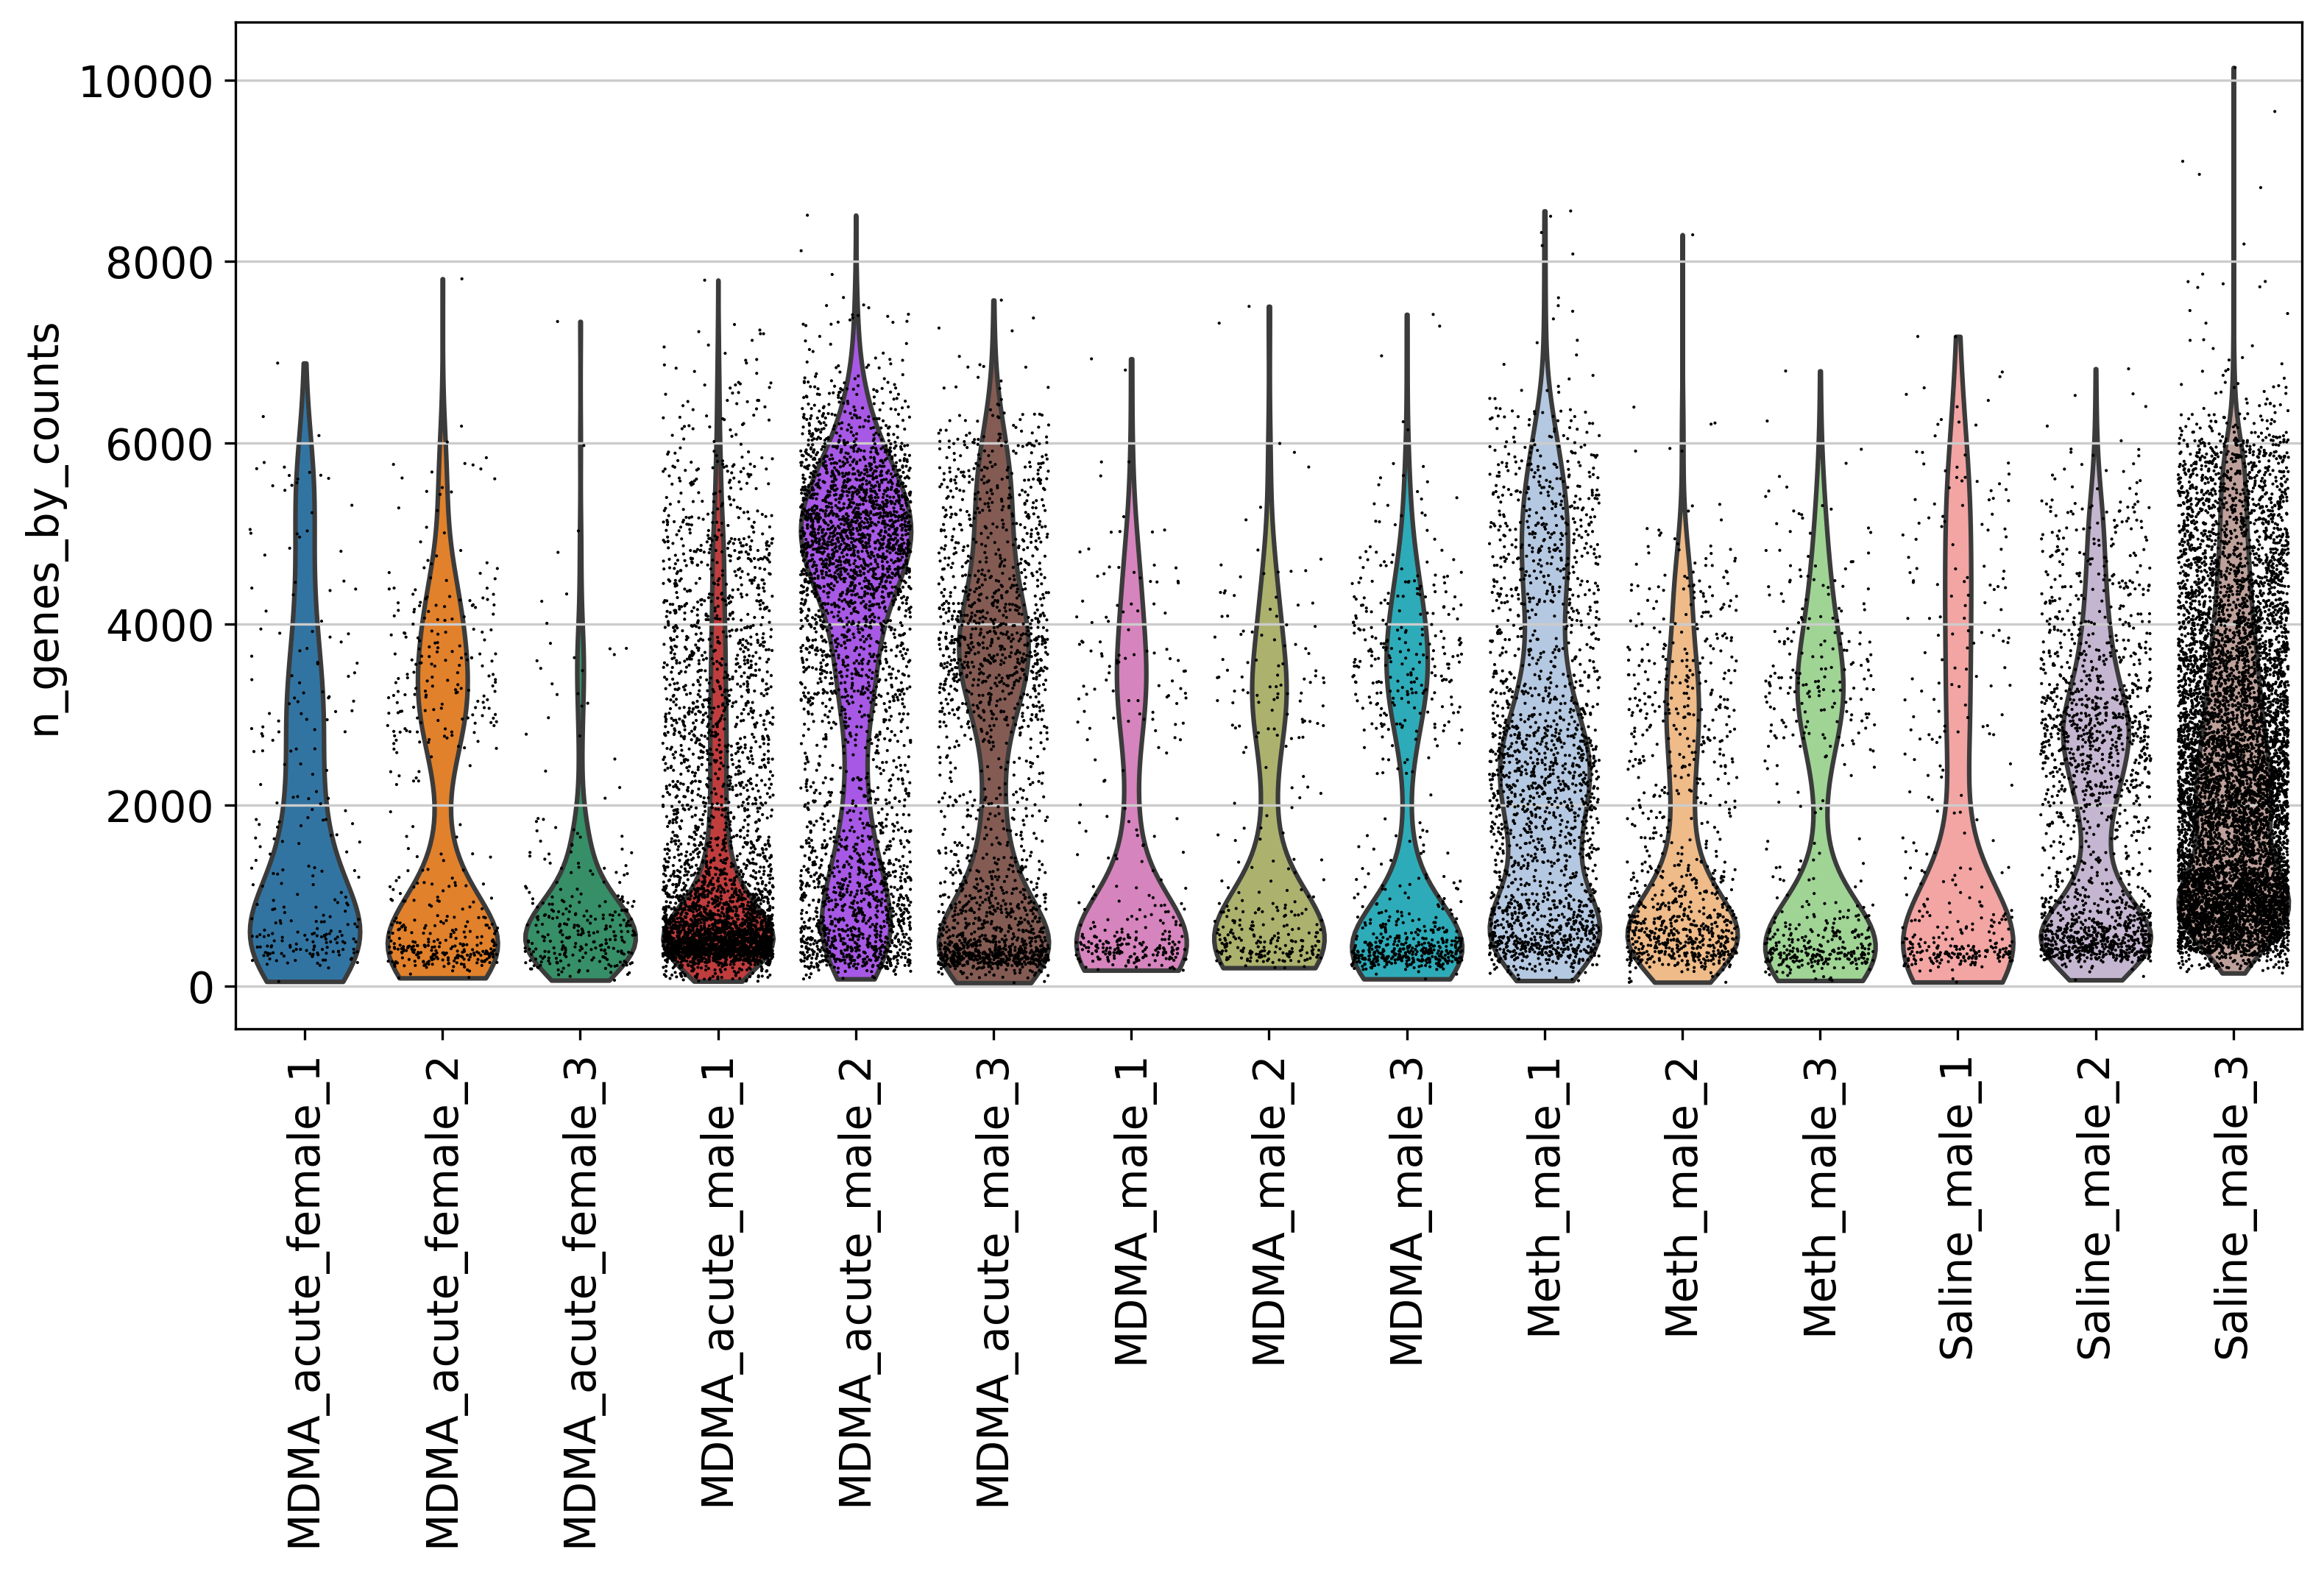

total_counts


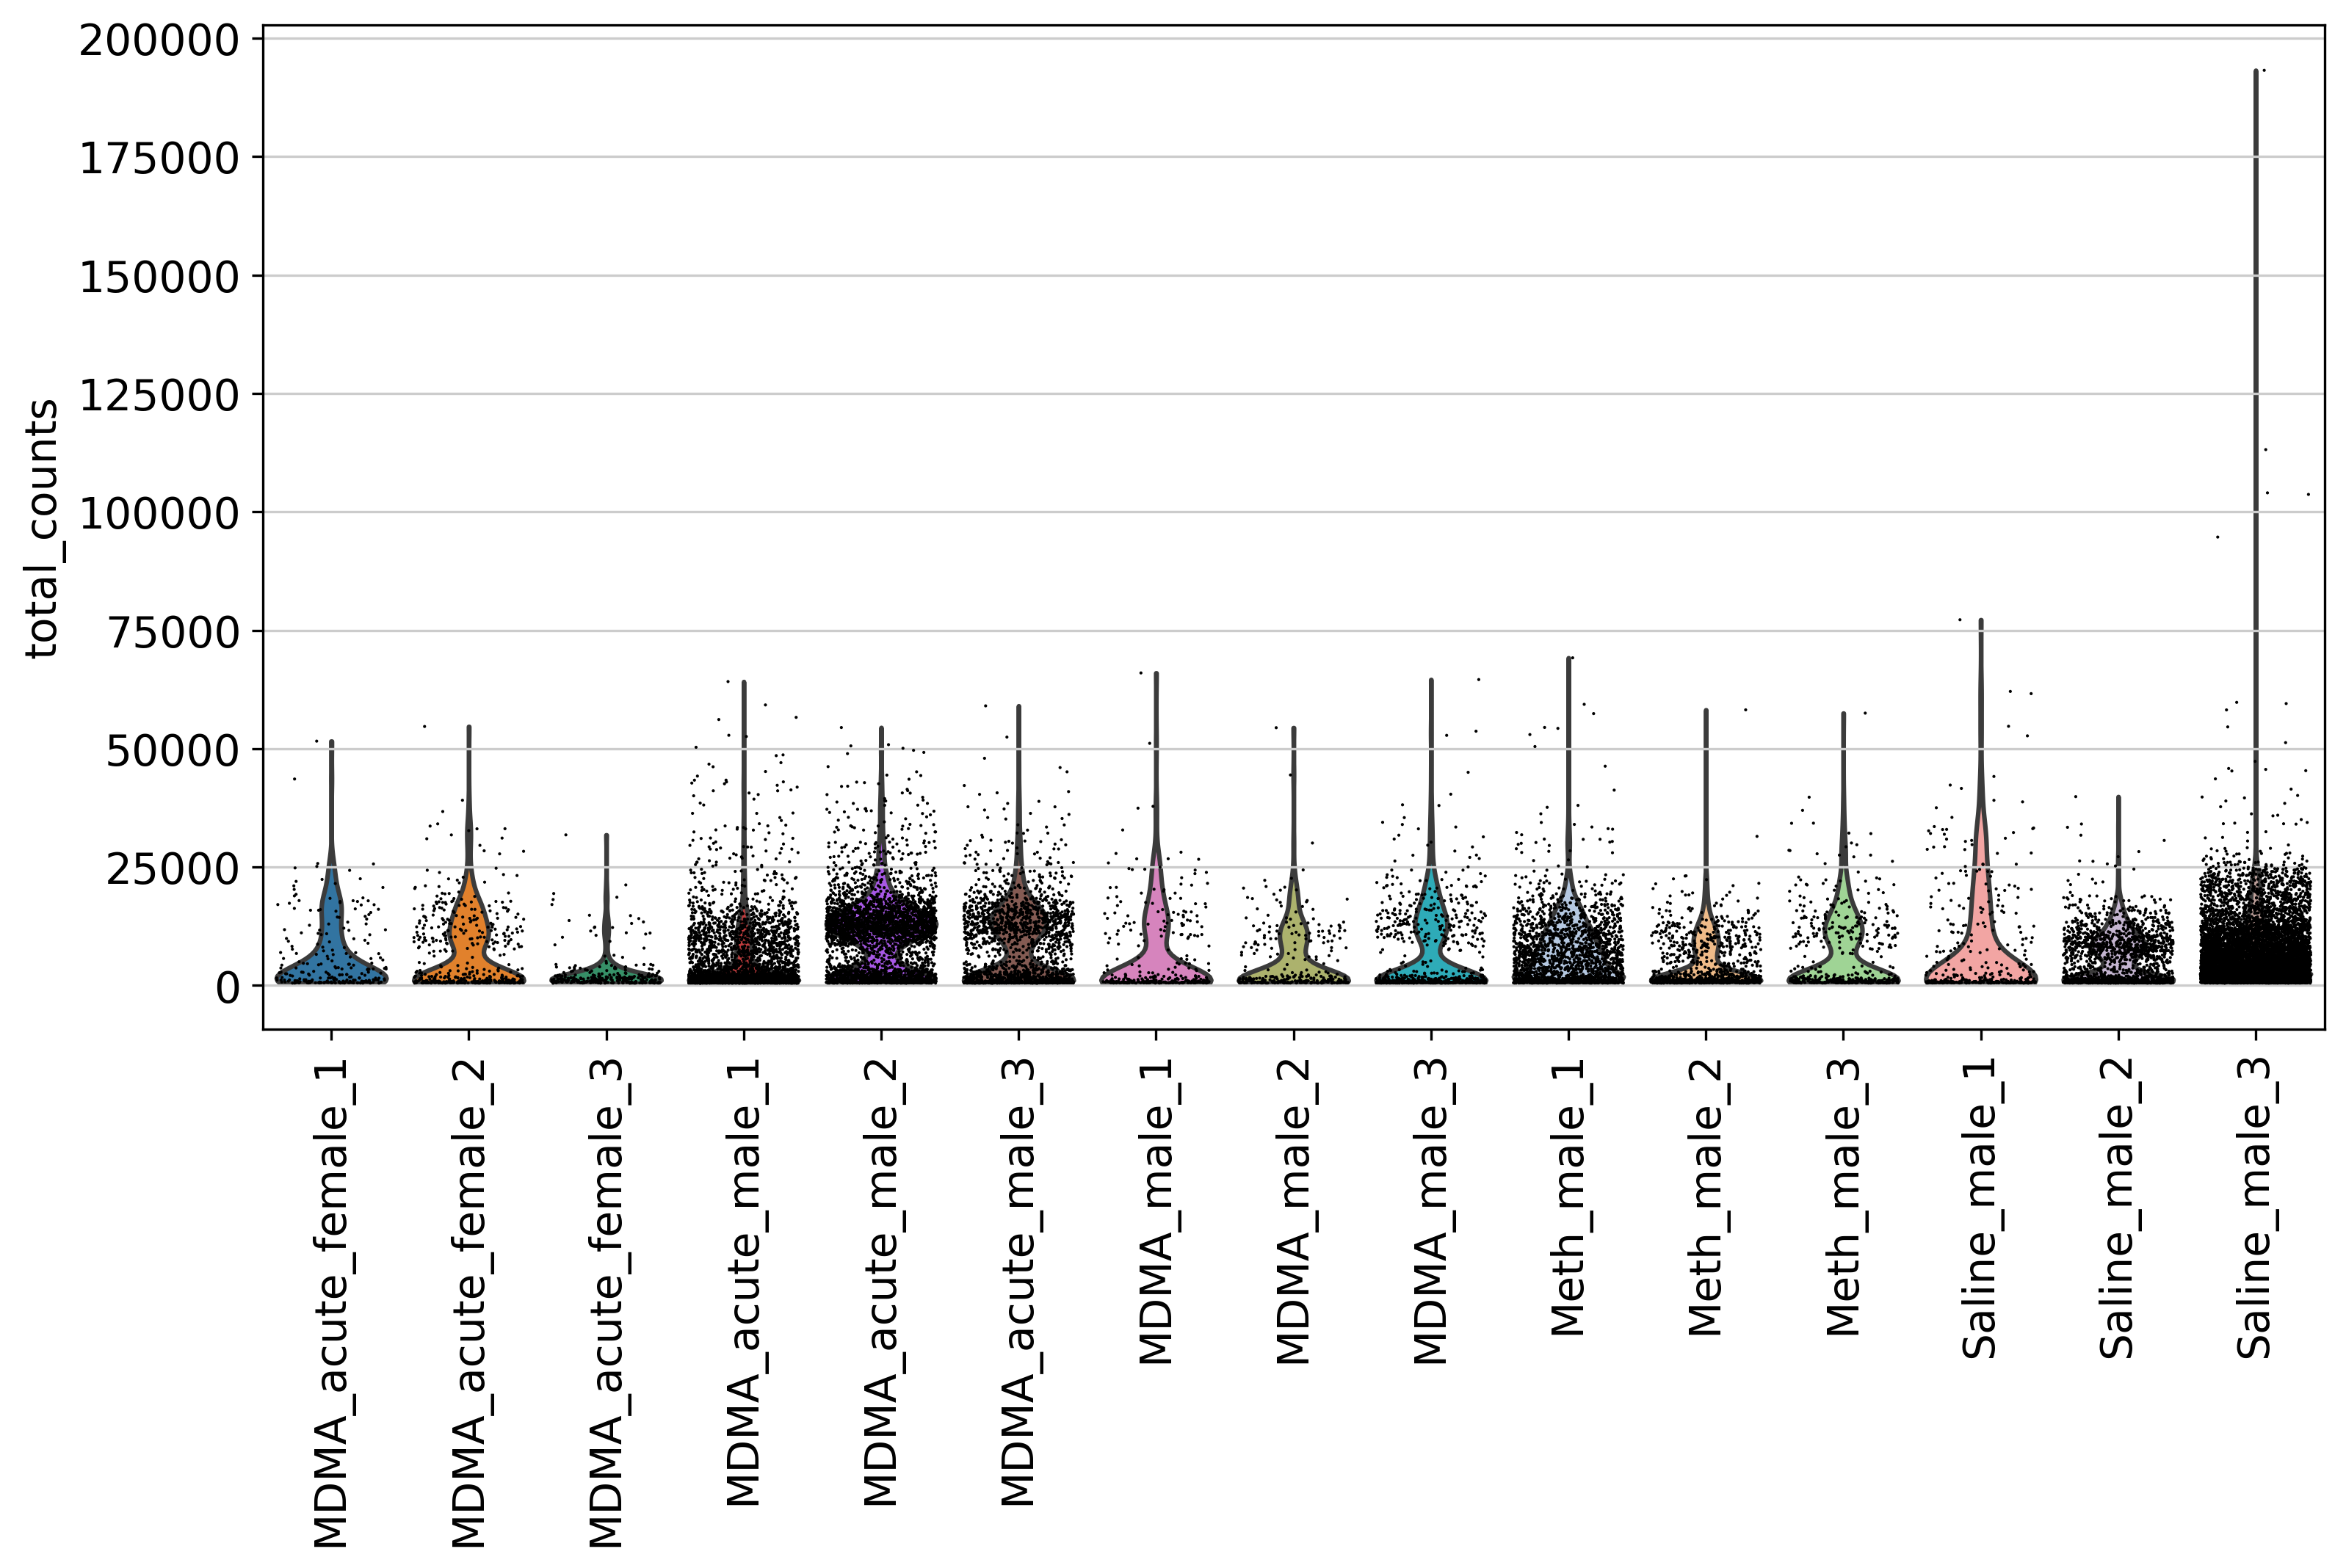

pct_counts_mt


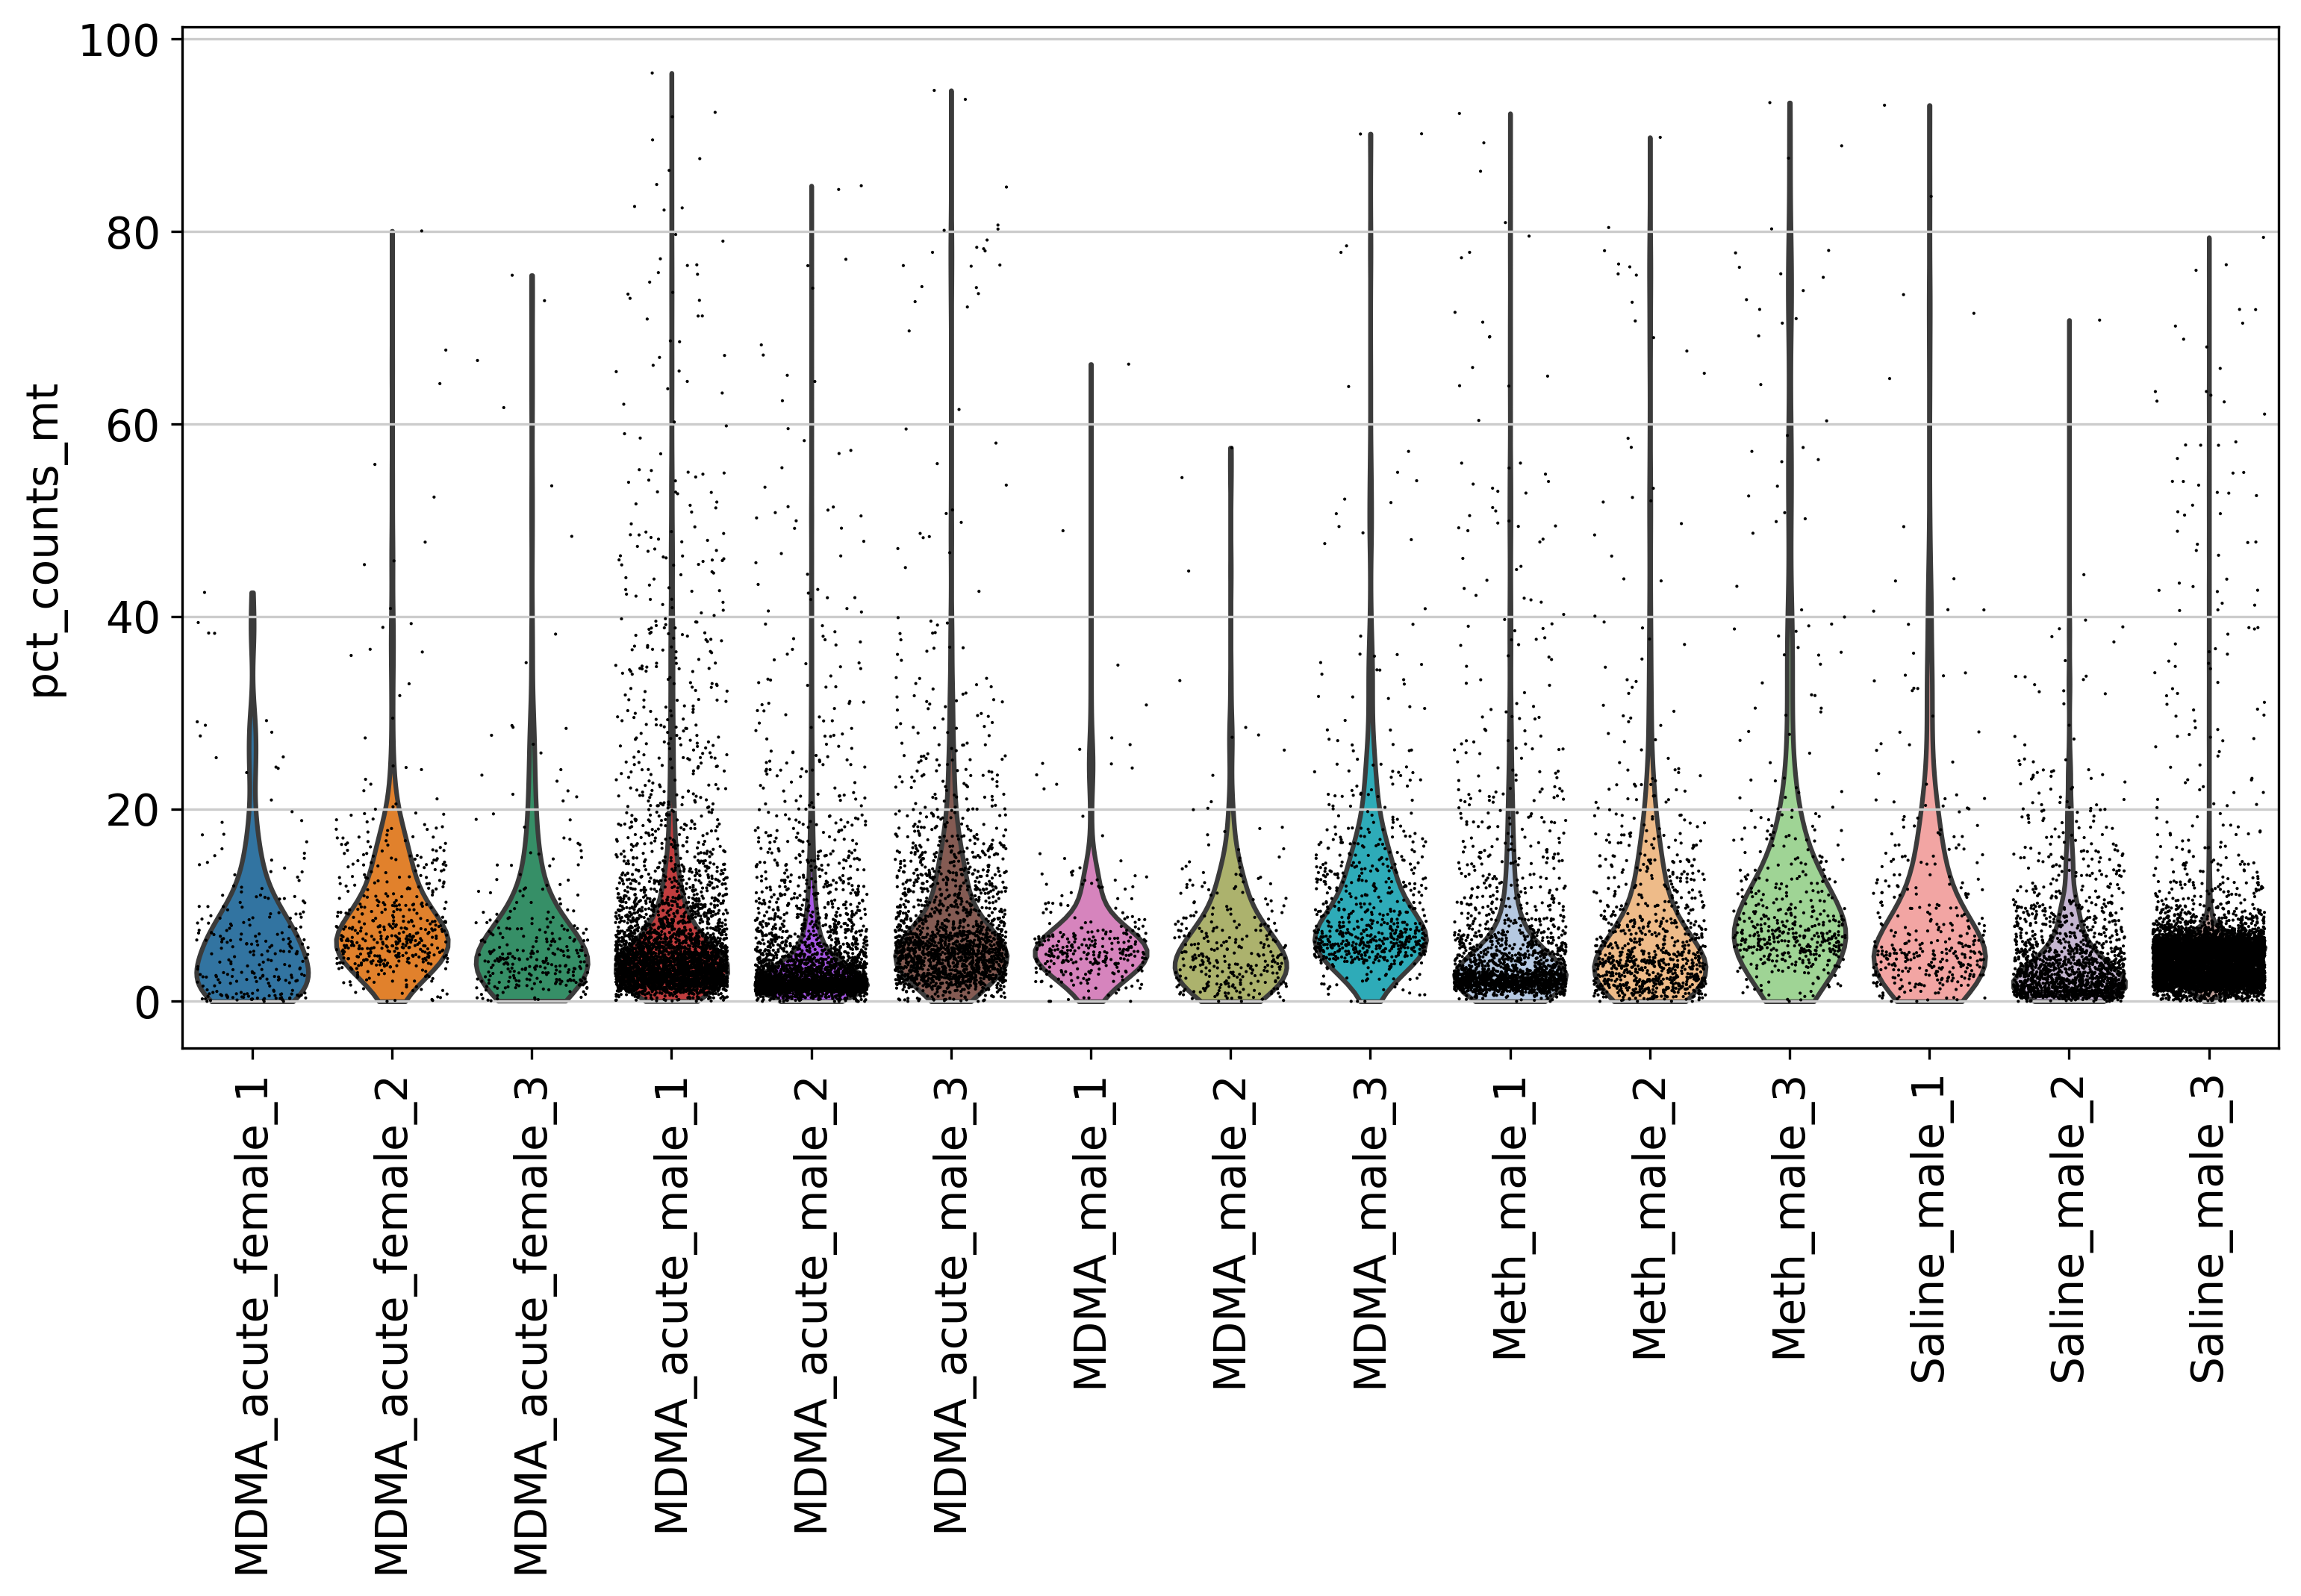

In [23]:
pdf_pages = PdfPages(f'figures/violin_mitochondrial_{cond}.pdf')
for col in [
    'n_genes_by_counts','total_counts',
    'pct_counts_mt'
]:
    # Create a figure instance (ie. a new page)
    fig = plot.figure(figsize=(12, 6), dpi=300)
    # Plot whatever you wish to plot
    print ('\033[1m' + col)
    ax = plt.subplot()
    sc.pl.violin(
        adata, col, jitter=0.4, groupby='batch', 
        multi_panel=True, ax=ax,rotation=90
    )
    # Done with the page
    pdf_pages.savefig(fig,bbox_inches='tight')
# Write the PDF document to the disk
pdf_pages.close()

### Actual filtering 

In [24]:
adata_flt_mt = filter_mt(adata,n=20)

`filter_mt` -> from #24816 cells filter #1194!


In [25]:
adata_flt_dd = remove_doublet(adata_flt_mt)

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:138: UserWarning: Revieved a view of an AnnData. Making a copy.
  view_to_actual(adata)
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


Automatically set threshold at doublet score = 0.50
Detected doublet rate = 0.4%
Estimated detectable doublet fraction = 39.6%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 0.9%


Trying to set attribute `.obs` of view, copying.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [26]:
for col in adata_flt_dd.var.columns: 
    del adata_flt_dd.var[col]

for col in adata_flt_dd.obs.columns: 
    if col == 'batch' or col == 'cond':
        pass
    else:
        del adata_flt_dd.obs[col]
del adata_flt_dd.uns

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [27]:
results_file = 'preprocessing/adatas-merge-reps-clean.h5ad.gz'
adata_flt_dd.write(results_file,compression='gzip')

In [28]:
!ls -s --block-size=M preprocessing/adatas-merge-reps-clean.h5ad.gz

384M preprocessing/adatas-merge-reps-clean.h5ad.gz


In [51]:
writer = pd.ExcelWriter('preprocessing/cell-counts.xlsx', engine='xlsxwriter')

# Write each dataframe to a different worksheet.
pd.concat([
    adata.obs.groupby('cond').size(),
    adata_flt_mt.obs.groupby('cond').size(),
    adata_flt_dd.obs.groupby('cond').size()
],axis=1).rename(columns={
    0:'raw',1:'mt filtering',2:'doublet filtering'
}).to_excel(writer,sheet_name='conditions')

pd.concat([
    adata.obs.groupby('batch').size(),
    adata_flt_mt.obs.groupby('batch').size(),
    adata_flt_dd.obs.groupby('batch').size()
],axis=1).rename(columns={
    0:'raw',1:'mt filtering',2:'doublet filtering'
}).to_excel(writer,sheet_name='batches')

# Close the Pandas Excel writer and output the Excel file.
writer.save()

## Clustering 

In [30]:
def clustering(adata,lognorm=False,rep=None, n_neighbor=30,res=None):
    if lognorm: 
        sc.pp.log1p(adata)
    sc.pp.pca(adata)
    sc.pp.neighbors(adata, use_rep=rep, n_neighbors=n_neighbor)   # why can't we just work with the default neighbors?
    sc.tl.umap(adata)
    sc.tl.leiden(adata,resolution=res)


In [31]:
adata2 = adata_flt_dd.copy()

Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [32]:
sc.pp.normalize_total(adata2, target_sum=1e4)

In [33]:
sc.pp.log1p(adata)

In [34]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)

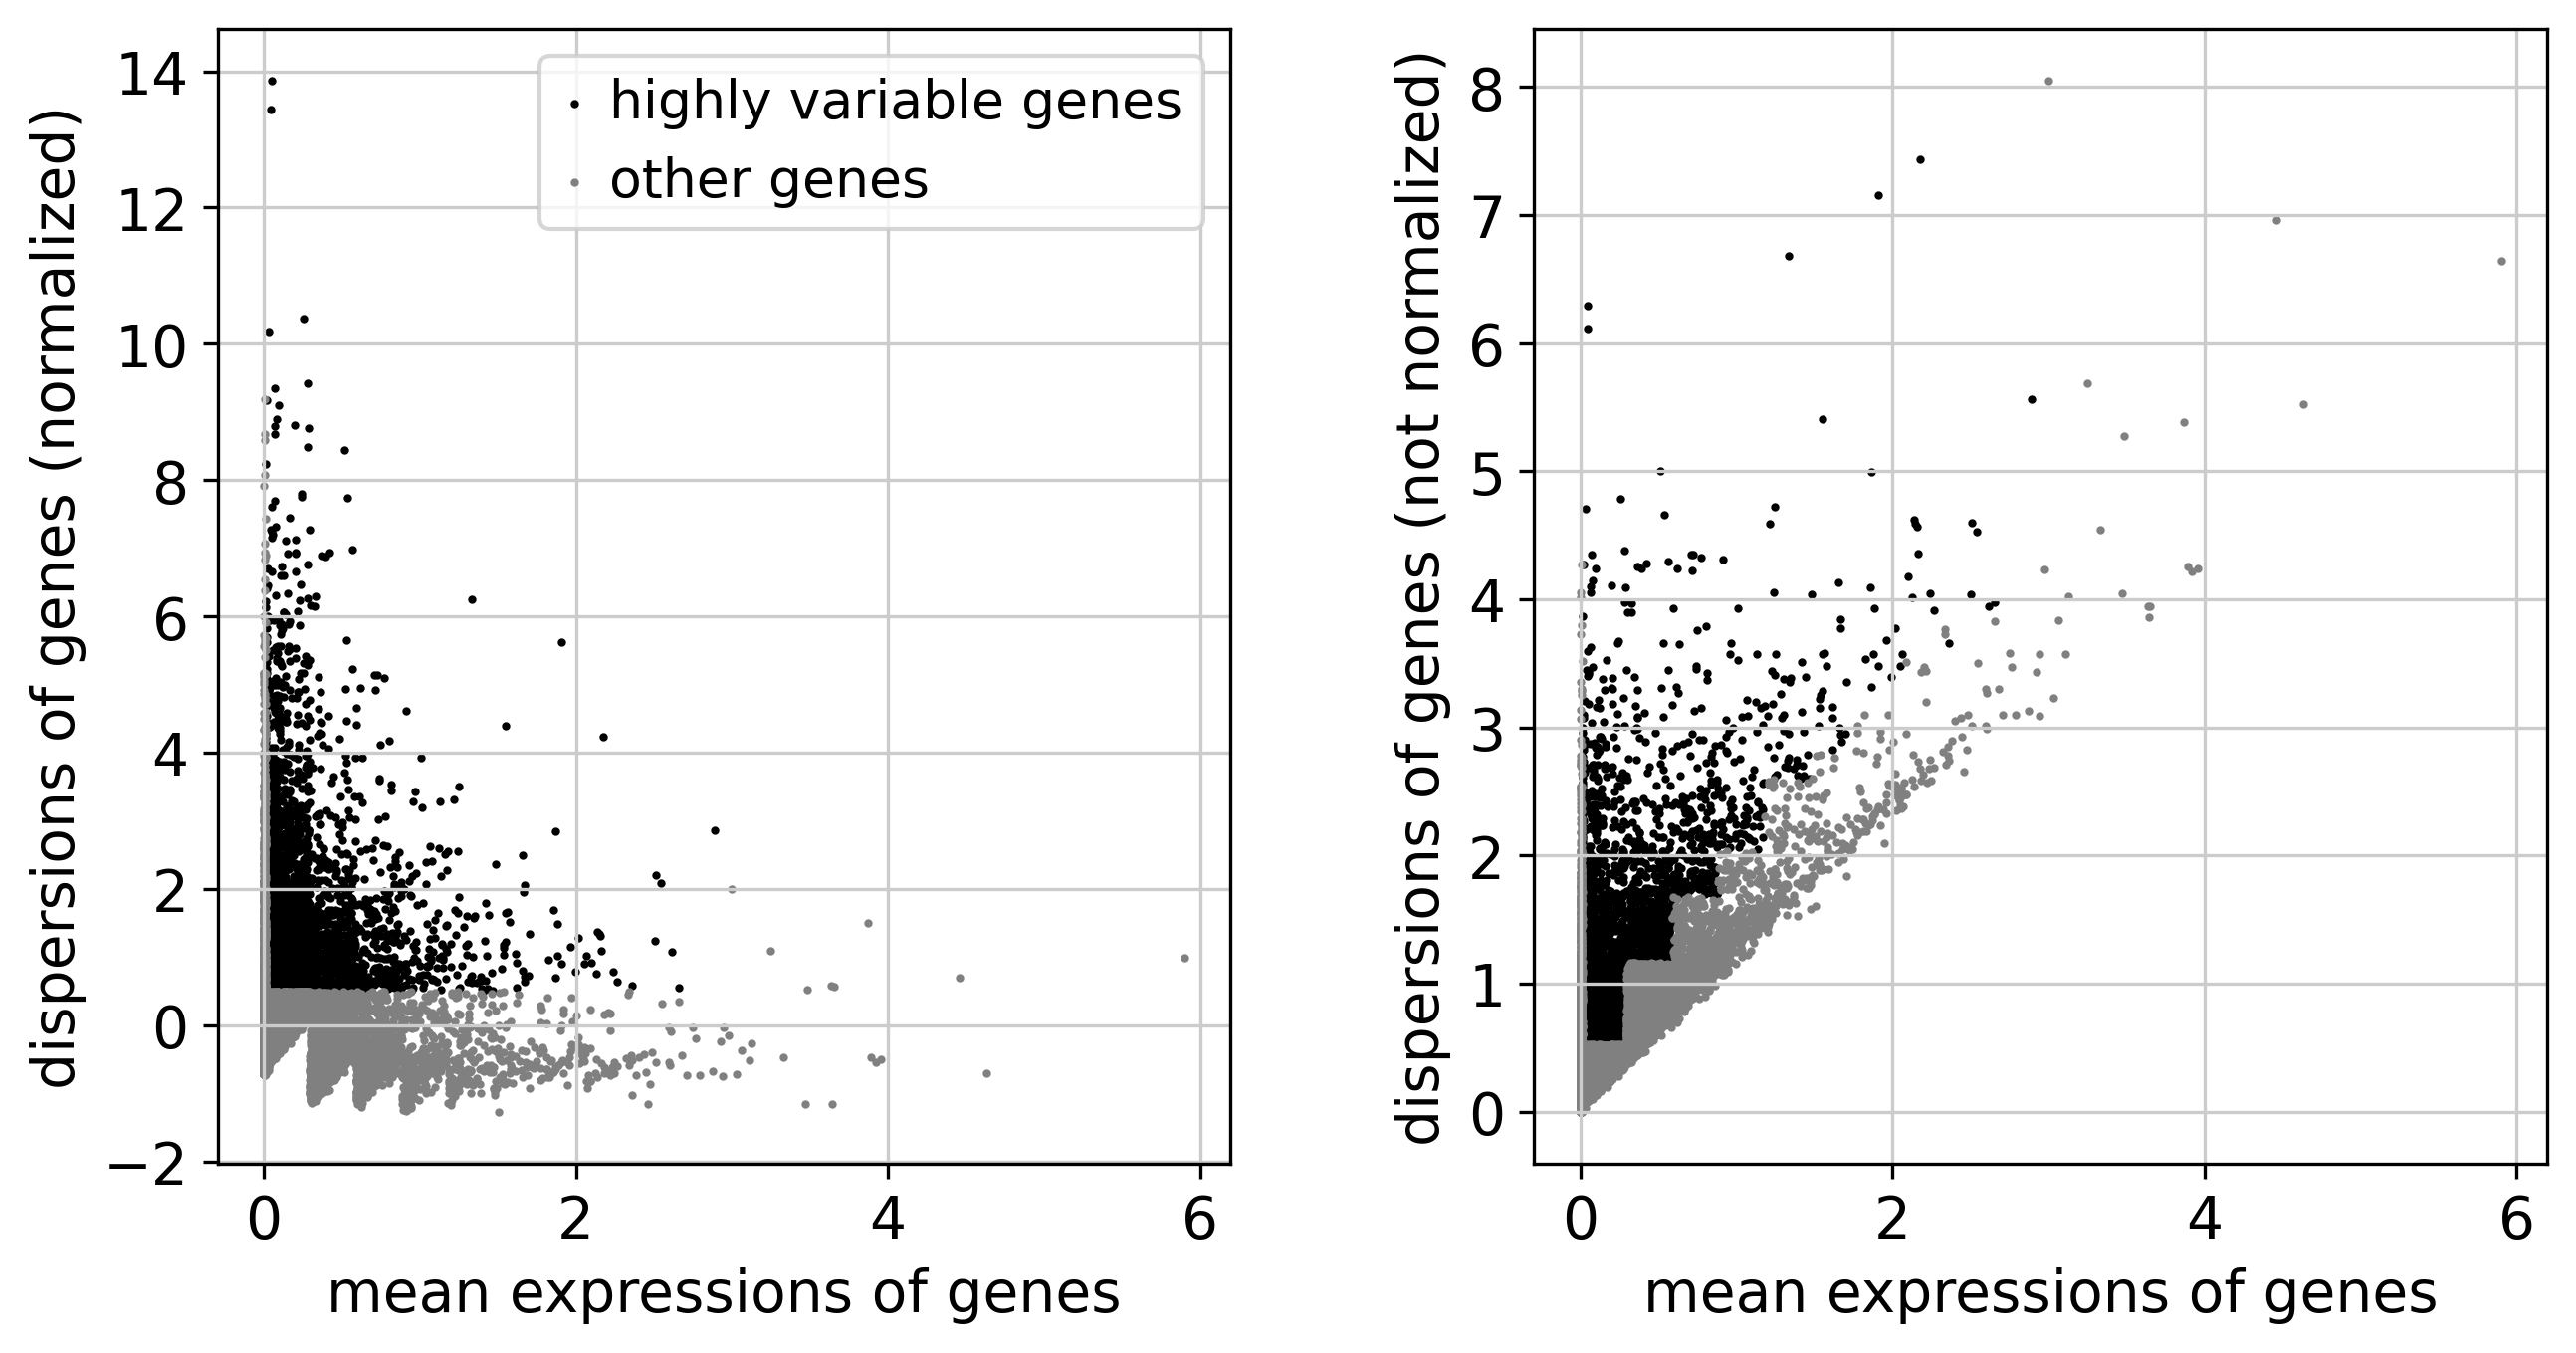

In [35]:
sc.pl.highly_variable_genes(adata)

In [36]:
clustering(adata2)

In [37]:
sc.pl.umap(adata2, color='cond',save='_cond.pdf')

In [38]:
sc.pl.umap(adata2, color='batch',save='_batch.pdf')

In [39]:
sc.tl.rank_genes_groups(adata2, 'leiden', method='logreg')

/data_gilbert/home/aarab/anaconda3/envs/sc-analysis/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:814: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [40]:
rank_genes_df = pd.DataFrame(adata2.uns['rank_genes_groups']['names'])

In [41]:
rank_genes_df.to_excel("celltyping/rank_genes_df.xlsx",
             sheet_name='leiden clusters')

In [42]:
adata2.var_names_make_unique()

In [43]:
sc.pl.violin(
    adata2,
    list({gene for l in rank_genes_df.head(1).values.tolist() for gene in l}), 
    groupby='cond',save='_rank_genes_groups.png',rotation=90
)

In [44]:
sc.pl.rank_genes_groups(adata2, n_genes=20, sharey=False,save='.pdf')

In [45]:
sc.pl.stacked_violin(
    adata2,
    list({gene for l in rank_genes_df.head(3).values.tolist() for gene in l}), 
    groupby='leiden',
    # title='mRNA Clusters',
    save='leiden.pdf',
    dendrogram=True
)

In [46]:
sc.pl.stacked_violin(
    adata2,
    list({gene for l in rank_genes_df.head(3).values.tolist() for gene in l}), 
    groupby='cond',
    # title='mRNA Clusters',
    save='cond.pdf',
    dendrogram=True
)

# 

In [52]:
!date

Wed Apr 27 15:50:17 PDT 2022
